# Лабораторная работа №10: Эффективный fine-tuning VLM с помощью Unsloth

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Повторить SFT на том же датасете через Unsloth.
- Сравнить LoRA rank и accumulation короткими runs.
- Построить quality-time-memory benchmark.


## Теоретическая часть

Эта работа оценивает не новый task, а efficiency: wall-clock, peak VRAM, throughput и качество при близких hyperparameters. Ускорение без эквивалентного evaluation не является результатом.


### Математическая постановка

Throughput $=N_{tokens}/T$, peak memory берётся из `torch.cuda.max_memory_allocated()`. Полезно строить Pareto frontier по quality, time и memory.


### Материалы

- [Unsloth docs](https://docs.unsloth.ai/)
- [PEFT](https://huggingface.co/docs/peft/index)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практический протокол

Тот же manifest и та же Qwen2.5-VL, что в работе 9. В Colab требуется совместимая пара версий Unsloth и TRL; зафиксируйте версии и аппаратное обеспечение. `FAST_DEV_RUN=True` всё равно запускает обучение, но только для smoke. Отсутствующие данные или GPU приводят к явной ошибке, а не к демонстрационному benchmark.

In [1]:
from pathlib import Path
import json, os, random, time
import numpy as np
SEED = 42
FAST_DEV_RUN = False  # True: проверка механики на малой выборке, НЕ отчётный эксперимент
ARTIFACTS = Path('artifacts'); ARTIFACTS.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
def save_json(name, data):
    (ARTIFACTS/name).write_text(json.dumps(data, ensure_ascii=False, indent=2, default=str))
from pathlib import Path
import json, hashlib
from datasets import load_dataset

SCIENCEQA_ID = 'derek-thomas/ScienceQA'
SCIENCEQA_REVISION = 'f18b0a70359ebfb41f658fd564208d0355b013f4'

def prepare_scienceqa(directory, smoke=False):
    """Fixed official splits, image-level deduplication, explicitly defined shifts."""
    directory = Path(directory).resolve(); directory.mkdir(parents=True, exist_ok=True)
    manifest = directory / ('manifest-smoke.jsonl' if smoke else 'manifest.jsonl')
    limits = {'train': 8 if smoke else 512, 'validation': 4 if smoke else 64,
              'id_test': 4 if smoke else 64, 'ood_test': 4 if smoke else 64,
              'general_test': 4 if smoke else 64}
    if manifest.exists():
        records = [json.loads(s) for s in manifest.read_text().splitlines()]
        if all(Path(r['image']).is_file() for r in records) and all(sum(r['split']==s for r in records)==n for s,n in limits.items()):
            return manifest
    records, seen, counts = [], set(), dict.fromkeys(limits, 0)
    for official in ('train', 'validation', 'test'):
        data = load_dataset(SCIENCEQA_ID, revision=SCIENCEQA_REVISION, split=official, streaming=True)
        for index, row in enumerate(data):
            image = row['image']
            if image is None: continue
            if official != 'test':
                if row['subject'] != 'natural science' or int(row['grade'].removeprefix('grade')) > 6: continue
                split = official
            elif row['subject'] != 'natural science': split = 'general_test'
            elif int(row['grade'].removeprefix('grade')) > 6: split = 'ood_test'
            else: split = 'id_test'
            if counts[split] >= limits[split]: continue
            image = image.convert('RGB')
            digest = hashlib.sha256(str(image.size).encode()+image.tobytes()).hexdigest()
            if digest in seen: continue
            seen.add(digest)
            path = directory / f'{digest}.png'; image.save(path)
            answer = int(row['answer']); choices = row['choices']
            question = row['question']+'\n'+'\n'.join(f'{chr(65+i)}. {v}' for i,v in enumerate(choices))+'\nReturn only the letter of the correct option.'
            records.append({'id': f'scienceqa-{official}-{index}', 'split': split,
                            'image': str(path), 'question': question, 'answer': chr(65+answer),
                            'choices': choices, 'answer_index': answer, 'label_type': 'multiple_choice',
                            'license': 'MIT (code license, lupantech/ScienceQA)',
                            'source_url': f'https://huggingface.co/datasets/{SCIENCEQA_ID}/tree/{SCIENCEQA_REVISION}',
                            'subject':row['subject'], 'grade':row['grade'], 'image_sha256':digest})
            counts[split] += 1
            required = [official] if official != 'test' else ['id_test','ood_test','general_test']
            if all(counts[s] == limits[s] for s in required): break
    if counts != limits: raise RuntimeError(f'Insufficient licensed image examples: {counts}; expected {limits}')
    manifest.write_text('\n'.join(json.dumps(r,ensure_ascii=False) for r in records)+'\n')
    (directory/'ATTRIBUTION.md').write_text('ScienceQA — Lu et al., NeurIPS 2022. Dataset distribution: '+SCIENCEQA_ID+'\nRevision: '+SCIENCEQA_REVISION+'\nDataset-card license: CC-BY-SA-4.0, https://creativecommons.org/licenses/by-sa/4.0/\nOriginal project: https://scienceqa.github.io/\nImage subsets and manifests retain attribution; downloaded images are not committed to this course.\nID: natural science grades 1–6; OOD: natural science grades 7–12; general: other subjects. This is an operational shift, not a claim of universal model ability.\n')
    return manifest


## Оценивание

Десять обязательных предметных этапов — по 1 баллу каждый, всего 10 баллов. Отдельное творческое исследование — до 1 дополнительного балла. Каждый этап принимается по указанному наблюдаемому результату.

### Одинаковые данные для сравнения

*Вес: 1 балл.*

**Постановка.** Загрузите ту же фиксированную ScienceQA-подвыборку через prepare_scienceqa, что в работе 09. Для сравнения библиотек нельзя менять наборы, вопросы или разбиения.

**Результат.** Манифест и изображения.

**Критерий принятия.** ID/хеши записей совпадают с протоколом 09; train и test не пересекаются.


In [3]:
# Реализуйте это задание по постановке выше.
# Артефакт: манифест и изображения из работы SFT
from pathlib import Path
import json, hashlib
DATA_DIR=Path("data/lab10")
manifest=prepare_scienceqa(DATA_DIR,smoke=FAST_DEV_RUN)
records=[json.loads(x) for x in manifest.read_text().splitlines()]
splits={s:[r for r in records if r["split"]==s] for s in ("train","validation","id_test","ood_test","general_test")}
assert all(splits.values()),"Один из split пуст"
assert all(Path(r["image"]).is_file() for r in records),"Отсутствуют изображения"
assert len({r["id"] for r in records})==len(records),"Повторяются ID"
assert len({r["image_sha256"] for r in records})==len(records),"Повторяются изображения"
assert not ({r["id"] for r in splits["train"]}&{r["id"] for s in ("id_test","ood_test","general_test") for r in splits[s]})
print("Manifest:",manifest)
for s,rows in splits.items(): print(s,len(rows))
print("Пример:",json.dumps(records[0],ensure_ascii=False,indent=2)[:1200])
save_json("data_manifest.json",{"path":str(manifest),"counts":{s:len(v) for s,v in splits.items()},"sha256":hashlib.sha256(manifest.read_bytes()).hexdigest()})

Manifest: /content/data/lab10/manifest.jsonl
train 512
validation 64
id_test 64
ood_test 64
general_test 64
Пример: {
  "id": "scienceqa-train-9",
  "split": "train",
  "image": "/content/data/lab10/7059b2a9d6213ab2b6bc531c6adaa60811f86552fb2ac3b6acf1244b0485c5b9.png",
  "question": "Which of these organisms contains matter that was once part of the phytoplankton?\nA. black rockfish\nB. sea otter\nReturn only the letter of the correct option.",
  "answer": "A",
  "choices": [
    "black rockfish",
    "sea otter"
  ],
  "answer_index": 0,
  "label_type": "multiple_choice",
  "license": "MIT (code license, lupantech/ScienceQA)",
  "source_url": "https://huggingface.co/datasets/derek-thomas/ScienceQA/tree/f18b0a70359ebfb41f658fd564208d0355b013f4",
  "subject": "natural science",
  "grade": "grade6",
  "image_sha256": "7059b2a9d6213ab2b6bc531c6adaa60811f86552fb2ac3b6acf1244b0485c5b9"
}


### Равный вычислительный бюджет

*Вес: 1 балл.*

**Постановка.** Зафиксируйте Qwen2.5-VL-3B-Instruct, GPU, 100 optimizer steps и accumulation 16. Сравнивайте ранги 8 и 16 при одинаковом количестве обработанных примеров.

**Результат.** protocol.json.

**Критерий принятия.** Сохранены GPU, модель, размеры выборок и бюджет; для обеих серий указан один seed.


In [4]:
# Реализуйте это задание по постановке выше.
# Артефакт: artifacts/protocol.json с GPU, шагами и размером train/test
import torch,platform,importlib.metadata as md
assert torch.cuda.is_available(),"Для этой лабораторной необходима CUDA GPU"
MODEL_NAME="unsloth/Qwen2.5-VL-3B-Instruct"
STEPS=2 if FAST_DEV_RUN else 100
ACCUMULATION=16
MICRO_BATCH=1
EFFECTIVE_BATCH=MICRO_BATCH*ACCUMULATION
protocol={"seed":SEED,"fast_dev_run":FAST_DEV_RUN,"model":MODEL_NAME,"gpu":torch.cuda.get_device_name(0),"cuda":torch.version.cuda,"torch":torch.__version__,"python":platform.python_version(),"steps":STEPS,"gradient_accumulation_steps":ACCUMULATION,"micro_batch_size":MICRO_BATCH,"effective_batch_size":EFFECTIVE_BATCH,"train_size":len(splits["train"]),"validation_size":len(splits["validation"]),"id_test_size":len(splits["id_test"]),"ood_test_size":len(splits["ood_test"]),"general_test_size":len(splits["general_test"]),"seed_r8":SEED,"seed_r16":SEED}
for pkg in ("unsloth","trl","transformers","peft","datasets"):
    try: protocol[pkg]=md.version(pkg)
    except md.PackageNotFoundError: protocol[pkg]="not installed"
save_json("protocol.json",protocol)
print(json.dumps(protocol,ensure_ascii=False,indent=2))

{
  "seed": 42,
  "fast_dev_run": false,
  "model": "unsloth/Qwen2.5-VL-3B-Instruct",
  "gpu": "Tesla T4",
  "cuda": "13.0",
  "torch": "2.11.0+cu130",
  "python": "3.13.16",
  "steps": 100,
  "gradient_accumulation_steps": 16,
  "micro_batch_size": 1,
  "effective_batch_size": 16,
  "train_size": 512,
  "validation_size": 64,
  "id_test_size": 64,
  "ood_test_size": 64,
  "general_test_size": 64,
  "seed_r8": 42,
  "seed_r16": 42,
  "unsloth": "not installed",
  "trl": "not installed",
  "transformers": "5.21.0",
  "peft": "0.21.2",
  "datasets": "4.8.5"
}


### Цикл мультимодального SFT

*Вес: 1 балл.*

**Постановка.** Реализуйте train_adapter с UnslothVisionDataCollator, AdamW, накоплением градиентов и ограничением их нормы. Измеряйте время с CUDA synchronize, сохраняйте историю loss и обученный адаптер.

**Результат.** Функция train_adapter.

**Критерий принятия.** На каждый optimizer step приходится accumulation микробатчей; измерения реальны; нечисловой loss вызывает ошибку.


In [7]:
# Реализуйте это задание по постановке выше.
# Артефакт: FastVisionModel и измерительный протокол
import gc, math, time, torch
from PIL import Image
from torch.utils.data import DataLoader
from unsloth import FastVisionModel, is_bf16_supported
from unsloth.trainer import UnslothVisionDataCollator
from trl import SFTTrainer, SFTConfig
def make_train_rows(rows):
    result=[]
    for r in rows:
        image=Image.open(r["image"]).convert("RGB")
        result.append({"messages":[{"role":"user","content":[{"type":"image","image":image},{"type":"text","text":r["question"]}]},{"role":"assistant","content":[{"type":"text","text":r["answer"]}]}]})
    return result
train_rows=make_train_rows(splits["train"])
print("Обучающих примеров:",len(train_rows))
print("Структура первого примера:",[{k:(type(v).__name__ if k=="image" else str(v)[:120]) for k,v in part.items()} for part in train_rows[0]["messages"][0]["content"]])
def train_adapter(rank,alpha,output_name):
    from torch.utils.data import DataLoader
    out=ARTIFACTS/output_name
    out.mkdir(parents=True,exist_ok=True)
    model,processor=FastVisionModel.from_pretrained(MODEL_NAME,load_in_4bit=True,use_gradient_checkpointing="unsloth")
    model=FastVisionModel.get_peft_model(model,r=rank,lora_alpha=alpha,lora_dropout=0,bias="none",random_state=SEED,use_rslora=False,target_modules="all-linear",finetune_vision_layers=True,finetune_language_layers=True,finetune_attention_modules=True,finetune_mlp_modules=True)
    FastVisionModel.for_training(model)
    collator=UnslothVisionDataCollator(model,processor)
    optimizer=torch.optim.AdamW([p for p in model.parameters() if p.requires_grad],lr=2e-4,weight_decay=0.01)
    loader=DataLoader(train_rows,batch_size=MICRO_BATCH,shuffle=True,collate_fn=collator)
    iterator=iter(loader); history=[]; optimizer.zero_grad(set_to_none=True)
    torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats(); torch.cuda.synchronize(); start=time.perf_counter()
    for step in range(1,STEPS+1):
        accumulated=0.0
        for micro in range(ACCUMULATION):
            try: batch=next(iterator)
            except StopIteration: iterator=iter(loader); batch=next(iterator)
            batch={k:(v.to("cuda") if hasattr(v,"to") else v) for k,v in batch.items()}
            with torch.autocast("cuda",dtype=torch.bfloat16 if is_bf16_supported() else torch.float16):
                loss=model(**batch).loss/ACCUMULATION
            if not torch.isfinite(loss): raise RuntimeError(f"Некорректный loss на step={step}, micro={micro}: {loss.item()}")
            loss.backward(); accumulated+=loss.detach().float().item()
        torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad],1.0)
        optimizer.step(); optimizer.zero_grad(set_to_none=True)
        history.append({"step":step,"loss":accumulated})
        if step==1 or step%10==0 or step==STEPS: print(f"rank={rank} step={step}/{STEPS} loss={accumulated:.5f}")
    torch.cuda.synchronize(); elapsed=time.perf_counter()-start
    peak=torch.cuda.max_memory_allocated()/1024**3
    adapter_dir=out/"adapter"; model.save_pretrained(str(adapter_dir)); processor.save_pretrained(str(adapter_dir))
    result={"rank":rank,"alpha":alpha,"steps_completed":len(history),"gradient_accumulation_steps":ACCUMULATION,"effective_batch_size":EFFECTIVE_BATCH,"elapsed_seconds":elapsed,"peak_cuda_memory_gb":peak,"examples_per_second":len(history)*EFFECTIVE_BATCH/elapsed,"history":history,"adapter_dir":str(adapter_dir),"model":MODEL_NAME,"seed":SEED,"gpu":torch.cuda.get_device_name(0)}
    save_json(f"{output_name}_training.json",result)
    del model,processor,optimizer,loader,iterator
    gc.collect(); torch.cuda.empty_cache()
    return result
print("Подготовка завершена; steps =",STEPS)

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
Unsloth: xformers is installed but cannot load with torch 2.11.0+cu130 (it was built for 2.10.0+cu128), so PyTorch attention is used instead.
To install a matching xformers, run `unsloth install-kernels xformers`, or `pip uninstall xformers` to hide this. UNSLOTH_ENABLE_LOGGING=1 shows the full error.
🦥 Unsloth Zoo will now patch everything to make training faster!
Обучающих примеров: 512
Структура первого примера: [{'type': 'image', 'image': 'Image'}, {'type': 'text', 'text': 'Which of these organisms contains matter that was once part of the phytoplankton?\nA. black rockfish\nB. sea otter\nReturn '}]
Подготовка завершена; steps = 100


### LoRA ранга 8

*Вес: 1 балл.*

**Постановка.** Создайте FastVisionModel и LoRA rank 8, alpha 16. Обучите модель по общему протоколу и сохраните адаптер отдельно.

**Результат.** unsloth_r8_a16/adapter и training.json.

**Критерий принятия.** Фактически выполнено 100 optimizer steps; зафиксированы loss, время и пиковая CUDA-память.


In [8]:
# Реализуйте это задание по постановке выше.
# Артефакт: адаптер ранга 8 и измеренные ресурсы
result_r8=train_adapter(rank=8,alpha=16,output_name="unsloth_r8_a16")
print(json.dumps({k:v for k,v in result_r8.items() if k!="history"},ensure_ascii=False,indent=2))
assert result_r8["steps_completed"]==STEPS

==((====))==  Unsloth 2026.10.11: Fast Qwen2_5_Vl patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

Skipping model.language_model.layers.1.mlp.gate_proj: no quant_state found
Skipping model.language_model.layers.1.mlp.up_proj: no quant_state found
Skipping model.language_model.layers.1.mlp.down_proj: no quant_state found
Skipping model.language_model.layers.2.mlp.gate_proj: no quant_state found
Skipping model.language_model.layers.2.mlp.up_proj: no quant_state found
Skipping model.language_model.layers.2.mlp.down_proj: no quant_state found
Skipping model.language_model.layers.5.mlp.gate_proj: no quant_state found
Skipping model.language_model.layers.5.mlp.up_proj: no quant_state found
Skipping model.language_model.layers.5.mlp.down_proj: no quant_state found
Skipping model.language_model.layers.30.mlp.gate_proj: no quant_state found
Skipping model.language_model.layers.30.mlp.up_proj: no quant_state found
Skipping model.language_model.layers.30.mlp.down_proj: no quant_state found
Unsloth: compiling each transformer block as one region (Qwen2_5_VLDecoderLayer).
Unsloth: Model does not

Unsloth: Restored added_tokens_decoder metadata in artifacts/unsloth_r8_a16/adapter/tokenizer_config.json.


{
  "rank": 8,
  "alpha": 16,
  "steps_completed": 100,
  "gradient_accumulation_steps": 16,
  "effective_batch_size": 16,
  "elapsed_seconds": 1224.967477648,
  "peak_cuda_memory_gb": 4.058341979980469,
  "examples_per_second": 1.3061571259606675,
  "adapter_dir": "artifacts/unsloth_r8_a16/adapter",
  "model": "unsloth/Qwen2.5-VL-3B-Instruct",
  "seed": 42,
  "gpu": "Tesla T4"
}


### LoRA ранга 16

*Вес: 1 балл.*

**Постановка.** Повторите эксперимент с rank 16, alpha 32. Начинайте с исходной модели, а не с адаптера ранга 8.

**Результат.** unsloth_r16_a16/adapter и training.json.

**Критерий принятия.** Меняется только ранг и соответствующий alpha; порядок данных, число шагов и effective batch совпадают.


In [9]:
# Реализуйте это задание по постановке выше.
# Артефакт: адаптер ранга 16 и измеренные ресурсы
result_r16=train_adapter(rank=16,alpha=32,output_name="unsloth_r16_a32")
print(json.dumps({k:v for k,v in result_r16.items() if k!="history"},ensure_ascii=False,indent=2))
assert result_r16["steps_completed"]==STEPS

==((====))==  Unsloth 2026.10.11: Fast Qwen2_5_Vl patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

Skipping model.language_model.layers.1.mlp.gate_proj: no quant_state found
Skipping model.language_model.layers.1.mlp.up_proj: no quant_state found
Skipping model.language_model.layers.1.mlp.down_proj: no quant_state found
Skipping model.language_model.layers.2.mlp.gate_proj: no quant_state found
Skipping model.language_model.layers.2.mlp.up_proj: no quant_state found
Skipping model.language_model.layers.2.mlp.down_proj: no quant_state found
Skipping model.language_model.layers.5.mlp.gate_proj: no quant_state found
Skipping model.language_model.layers.5.mlp.up_proj: no quant_state found
Skipping model.language_model.layers.5.mlp.down_proj: no quant_state found
Skipping model.language_model.layers.30.mlp.gate_proj: no quant_state found
Skipping model.language_model.layers.30.mlp.up_proj: no quant_state found
Skipping model.language_model.layers.30.mlp.down_proj: no quant_state found
Unsloth: Model does not have a default image size - using 512
rank=16 step=1/100 loss=6.69221
rank=16 ste

Unsloth: Restored added_tokens_decoder metadata in artifacts/unsloth_r16_a32/adapter/tokenizer_config.json.


{
  "rank": 16,
  "alpha": 32,
  "steps_completed": 100,
  "gradient_accumulation_steps": 16,
  "effective_batch_size": 16,
  "elapsed_seconds": 1178.528286546,
  "peak_cuda_memory_gb": 4.380593776702881,
  "examples_per_second": 1.3576254539373327,
  "adapter_dir": "artifacts/unsloth_r16_a32/adapter",
  "model": "unsloth/Qwen2.5-VL-3B-Instruct",
  "seed": 42,
  "gpu": "Tesla T4"
}


### Траектории оптимизации

*Вес: 1 балл.*

**Постановка.** Постройте график loss по optimizer steps для двух рангов. Сопоставьте число шагов, время и пиковую память, прежде чем делать вывод о полезности большего ранга.

**Результат.** loss_comparison.png и benchmark.json.

**Критерий принятия.** График построен по реальным историям обучения, оси и ранги подписаны; отсутствующие измерения не заменены константой.


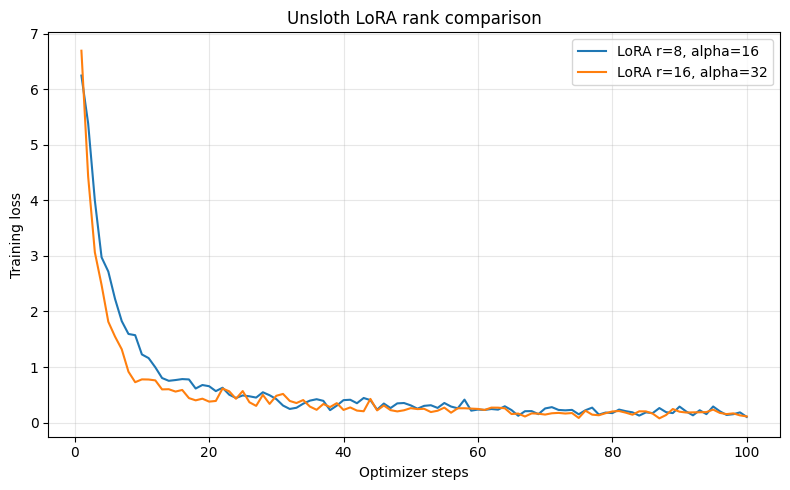

{
  "r8": {
    "rank": 8,
    "alpha": 16,
    "steps_completed": 100,
    "gradient_accumulation_steps": 16,
    "effective_batch_size": 16,
    "elapsed_seconds": 1224.967477648,
    "peak_cuda_memory_gb": 4.058341979980469,
    "examples_per_second": 1.3061571259606675,
    "adapter_dir": "artifacts/unsloth_r8_a16/adapter",
    "model": "unsloth/Qwen2.5-VL-3B-Instruct",
    "seed": 42,
    "gpu": "Tesla T4"
  },
  "r16": {
    "rank": 16,
    "alpha": 32,
    "steps_completed": 100,
    "gradient_accumulation_steps": 16,
    "effective_batch_size": 16,
    "elapsed_seconds": 1178.528286546,
    "peak_cuda_memory_gb": 4.380593776702881,
    "examples_per_second": 1.3576254539373327,
    "adapter_dir": "artifacts/unsloth_r16_a32/adapter",
    "model": "unsloth/Qwen2.5-VL-3B-Instruct",
    "seed": 42,
    "gpu": "Tesla T4"
  },
  "protocol": {
    "seed": 42,
    "fast_dev_run": false,
    "model": "unsloth/Qwen2.5-VL-3B-Instruct",
    "gpu": "Tesla T4",
    "cuda": "13.0",
    "torch

In [10]:
# Реализуйте это задание по постановке выше.
# Артефакт: два реально обученных адаптера в benchmark.json
import matplotlib.pyplot as plt
assert result_r8["steps_completed"]==result_r16["steps_completed"]
fig,ax=plt.subplots(figsize=(8,5))
ax.plot([x["step"] for x in result_r8["history"]],[x["loss"] for x in result_r8["history"]],label="LoRA r=8, alpha=16")
ax.plot([x["step"] for x in result_r16["history"]],[x["loss"] for x in result_r16["history"]],label="LoRA r=16, alpha=32")
ax.set_xlabel("Optimizer steps"); ax.set_ylabel("Training loss"); ax.set_title("Unsloth LoRA rank comparison"); ax.legend(); ax.grid(True,alpha=.3); fig.tight_layout()
fig.savefig(ARTIFACTS/"loss_comparison.png",dpi=160); plt.show()
benchmark={"r8":{k:v for k,v in result_r8.items() if k!="history"},"r16":{k:v for k,v in result_r16.items() if k!="history"},"protocol":protocol}
save_json("benchmark.json",benchmark)
print(json.dumps(benchmark,ensure_ascii=False,indent=2))

### Общий интерфейс инференса

*Вес: 1 балл.*

**Постановка.** Реализуйте один greedy-инференс для обоих адаптеров: общие processor, размер изображения, max_new_tokens и извлечение продолжения.

**Результат.** Функция infer.

**Критерий принятия.** Выход не содержит prompt; ответы получаются от активного адаптера на реальном изображении.


In [11]:
# Реализуйте это задание по постановке выше.
# Артефакт: функция инференса с общим декодированием
import gc, torch
from PIL import Image
from unsloth import FastVisionModel
def load_adapter(adapter_dir):
    model,processor=FastVisionModel.from_pretrained(MODEL_NAME,load_in_4bit=True)
    model.load_adapter(str(adapter_dir))
    FastVisionModel.for_inference(model)
    return model,processor
def infer(model,processor,image_path,question,max_new_tokens=8):
    image=Image.open(image_path).convert("RGB")
    messages=[{"role":"user","content":[{"type":"image","image":image},{"type":"text","text":question+"\nReturn only the letter of the correct option."}]}]
    prompt=processor.apply_chat_template(messages,tokenize=False,add_generation_prompt=True)
    inputs=processor(text=[prompt],images=[image],return_tensors="pt",padding=True)
    inputs={k:(v.to(model.device) if hasattr(v,"to") else v) for k,v in inputs.items()}
    with torch.inference_mode():
        generated=model.generate(**inputs,max_new_tokens=max_new_tokens,do_sample=False)
    prompt_len=inputs["input_ids"].shape[1]
    answer=processor.batch_decode(generated[:,prompt_len:],skip_special_tokens=True)[0].strip()
    return answer
print("Функция infer готова")

Функция infer готова


### Метрика и ошибки формата

*Вес: 1 балл.*

**Постановка.** Определите exact match правильной буквы и отдельную долю ответов допустимого формата A–Z. Реализуйте подсчёт по split с явными знаменателями; пустая выборка должна вызывать ошибку.

**Результат.** Функция evaluate_answers.

**Критерий принятия.** Верный ответ даёт EM=1, неверный и лишний текст — EM=0; n равен числу всех примеров split.


In [12]:
# Реализуйте это задание по постановке выше.
# Артефакт: контейнер попарных результатов
import re, json
LETTER_RE=re.compile(r"^\s*([A-Z])\s*[.!]?\s*$")
def normalize_answer(text):
    m=LETTER_RE.fullmatch(str(text))
    return m.group(1) if m else None
def evaluate_answers(rows,predictions):
    if not rows: raise ValueError("Нельзя оценивать пустую выборку")
    if len(rows)!=len(predictions): raise ValueError(f"Размеры не совпадают: rows={len(rows)}, predictions={len(predictions)}")
    exact=0; valid=0
    for row,pred in zip(rows,predictions):
        raw=str(pred).strip()
        letter=normalize_answer(raw)
        if letter is not None and "A"<=letter<="Z": valid+=1
        if letter==row["answer"]: exact+=1
    return {"n":len(rows),"exact_match":exact/len(rows),"correct":exact,"format_valid":valid/len(rows),"format_valid_n":valid}
print(evaluate_answers([{"answer":"A"}],["A"]))
assert evaluate_answers([{"answer":"A"}],["A"])["exact_match"]==1.0
assert evaluate_answers([{"answer":"A"}],["The answer is A"])["exact_match"]==0.0

{'n': 1, 'exact_match': 1.0, 'correct': 1, 'format_valid': 1.0, 'format_valid_n': 1}


### Качество двух адаптеров

*Вес: 1 балл.*

**Постановка.** Примените оба адаптера к одним ID/OOD изображениям и рассчитайте согласованные метрики. Сохраните исходный текст каждого ответа.

**Результат.** predictions_r8_a16.jsonl и predictions_r16_a16.jsonl.

**Критерий принятия.** Наборы ID совпадают между сериями; отчёт содержит exact match, format rate и n на ID/OOD.


In [13]:
# Реализуйте это задание по постановке выше.
# Артефакт: файлы предсказаний ID/OOD test
def run_adapter_predictions(rank,alpha,output_name):
    adapter_dir=ARTIFACTS/output_name/"adapter"
    model,processor=load_adapter(adapter_dir)
    output_path=ARTIFACTS/f"predictions_{output_name}.jsonl"
    summary={}
    try:
        with output_path.open("w",encoding="utf-8") as f:
            for split_name in ("id_test","ood_test"):
                rows=splits[split_name]; predictions=[]
                for i,row in enumerate(rows,1):
                    raw=infer(model,processor,row["image"],row["question"])
                    predictions.append(raw)
                    f.write(json.dumps({"id":row["id"],"split":split_name,"image":row["image"],"question":row["question"],"gold":row["answer"],"prediction":raw},ensure_ascii=False)+"\n")
                    if i==1 or i%10==0 or i==len(rows): print(f"{output_name} {split_name}: {i}/{len(rows)}")
                summary[split_name]=evaluate_answers(rows,predictions)
        save_json(f"evaluation_{output_name}.json",summary)
    finally:
        del model,processor; gc.collect(); torch.cuda.empty_cache()
    print(json.dumps(summary,ensure_ascii=False,indent=2))
    return {"file":str(output_path),"metrics":summary}
pred_r8=run_adapter_predictions(8,16,"unsloth_r8_a16")
pred_r16=run_adapter_predictions(16,32,"unsloth_r16_a32")

==((====))==  Unsloth 2026.10.11: Fast Qwen2_5_Vl patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

Skipping model.language_model.layers.1.mlp.gate_proj: no quant_state found
Skipping model.language_model.layers.1.mlp.up_proj: no quant_state found
Skipping model.language_model.layers.1.mlp.down_proj: no quant_state found
Skipping model.language_model.layers.2.mlp.gate_proj: no quant_state found
Skipping model.language_model.layers.2.mlp.up_proj: no quant_state found
Skipping model.language_model.layers.2.mlp.down_proj: no quant_state found
Skipping model.language_model.layers.5.mlp.gate_proj: no quant_state found
Skipping model.language_model.layers.5.mlp.up_proj: no quant_state found
Skipping model.language_model.layers.5.mlp.down_proj: no quant_state found
Skipping model.language_model.layers.30.mlp.gate_proj: no quant_state found
Skipping model.language_model.layers.30.mlp.up_proj: no quant_state found
Skipping model.language_model.layers.30.mlp.down_proj: no quant_state found


Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


...

unsloth_r16_a32 ood_test: 50/64


Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generati

unsloth_r16_a32 ood_test: 60/64


Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


unsloth_r16_a32 ood_test: 64/64
{
  "id_test": {
    "n": 64,
    "exact_match": 0.875,
    "correct": 56,
    "format_valid": 1.0,
    "format_valid_n": 64
  },
  "ood_test": {
    "n": 64,
    "exact_match": 0.640625,
    "correct": 41,
    "format_valid": 1.0,
    "format_valid_n": 64
  }
}


### Сравнение подходов

*Вес: 1 балл.*

**Постановка.** Сопоставьте качество двух рангов и результат LLaMA-Factory из работы 09. Скорость библиотек сравнивайте только при одинаковых GPU, шагах, effective batch и обучаемых модулях. Отсутствующий baseline обозначьте явно.

**Результат.** comparison.json и вывод.

**Критерий принятия.** Не заявлен speedup по несопоставимым измерениям; отсутствие baseline не выдано за нулевое качество; для полного сравнения приложен результат 09.


In [17]:
# Реализуйте это задание по постановке выше.
# Артефакт: artifacts/comparison.json с явным отсутствующим baseline
from pathlib import Path
import json
import pandas as pd
from IPython.display import display

# 1. Загружаем результаты лабораторной №9
ARTIFACTS = Path("artifacts")
eval_path = ARTIFACTS / "evaluation.json"
if not eval_path.is_file():
    raise FileNotFoundError(f"Не найден файл результатов Lab 9: {eval_path.resolve()}")

lab9_evaluation = json.loads(eval_path.read_text(encoding="utf-8"))
baseline = lab9_evaluation["splits"]

print("Результаты Lab 9 загружены:", eval_path.resolve())
print("Метрика Lab 9:", lab9_evaluation.get("metric", "не указана"))

# 2. Проверяем наличие результатов Lab 10
for name, result in [("pred_r8", pred_r8), ("pred_r16", pred_r16)]:
    if not isinstance(result, dict) or "metrics" not in result:
        raise ValueError(f"{name} не содержит словарь metrics. Проверьте предыдущие ячейки.")

# 3. Сравниваем метрики по каждому тестовому набору
rows = []
for split in ("id_test", "ood_test", "general_test"):
    if split not in baseline:
        print(f"Пропускаем {split}: отсутствует в evaluation.json Lab 9")
        continue
    old = baseline[split]
    for model_name, result in [("Unsloth LoRA r=8", pred_r8), ("Unsloth LoRA r=16", pred_r16)]:
        metrics = result["metrics"].get(split)
        if not metrics or "exact_match" not in metrics:
            print(f"Внимание: метрики {split} отсутствуют для {model_name}")
            continue
        lab9_sft = old["sft_exact_match"]
        lab10_em = metrics["exact_match"]
        rows.append({
            "Тестовый набор": split,
            "Lab 9 Base EM": old["base_exact_match"],
            "Lab 9 SFT EM": lab9_sft,
            "Lab 10 модель": model_name,
            "Lab 10 Exact Match": lab10_em,
            "Разница с Lab 9 SFT": lab10_em - lab9_sft
        })

if not rows:
    raise ValueError("Не удалось построить таблицу. Проверьте структуру metrics в pred_r8 и pred_r16.")

comparison_df = pd.DataFrame(rows)
display(comparison_df.round(4))

output_path = ARTIFACTS / "lab9_lab10_comparison.csv"
comparison_df.to_csv(output_path, index=False, encoding="utf-8-sig")
print(f"\nТаблица сравнения сохранена: {output_path.resolve()}")


Результаты Lab 9 загружены: /content/artifacts/evaluation.json
Метрика Lab 9: Strict Exact Match
Внимание: метрики general_test отсутствуют для Unsloth LoRA r=8
Внимание: метрики general_test отсутствуют для Unsloth LoRA r=16


,Тестовый набор,Lab 9 Base EM,Lab 9 SFT EM,Lab 10 модель,Lab 10 Exact Match,Разница с Lab 9 SFT
0,id_test,0.7969,0.8594,Unsloth LoRA r=8,0.8750,0.0156
1,id_test,0.7969,0.8594,Unsloth LoRA r=16,0.8750,0.0156
2,ood_test,0.5469,0.7031,Unsloth LoRA r=8,0.6562,-0.0469
3,ood_test,0.5469,0.7031,Unsloth LoRA r=16,0.6406,-0.0625



Таблица сравнения сохранена: /content/artifacts/lab9_lab10_comparison.csv


### Творческое мини-исследование

*Бонус: до 1 балла сверх 10.*

**Постановка.** Сформулируйте проверяемую гипотезу о предметном ограничении метода данной лабораторной и проверьте её на дополнительных реальных входах без использования отложенного теста для выбора гипотезы. Сопоставьте результаты с основным экспериментом и объясните расхождения.

**Результат.** Отдельный файл artifacts/bonus.md с гипотезой, протоколом, наблюдениями и выводом.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена по сохранённым предсказаниям или изображениям и приведено воспроизводимое сравнение.

In [ ]:
# Реализуйте творческое мини-исследование по постановке выше.
raise NotImplementedError("Реализуйте бонусное исследование")

## Анализ результатов

Сопоставьте измеренные показатели на фиксированной отложенной выборке, укажите ограничения выборки и разберите ошибки по сохранённым предсказаниям. FAST_DEV_RUN не является основанием для итогового вывода.

## Требования к сдаче

Запустите полный режим, приложите конфигурацию, версии зависимостей, артефакты и инструкции повторного запуска. Не сдавайте фиктивные измерения.